In [1]:
from pystormtracker.models.tracks import Tracks, TracksMetadata
from pystormtracker.metrics.compare import compare_tracks, TrackComparisonConfig
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import pandas as pd
import pystormtracker as pst
from pathlib import Path
import cartopy.crs as ccrs

import sys
import os

module_dir = (Path.cwd() / ".."/".." / "algorithms").resolve()
sys.path.insert(0,str(module_dir))
import validation as val
import processing as pro
import statistics_on_tracks as sot

import importlib
importlib.reload(val)  # pick up edits in validation.py without restarting the kernel
importlib.reload(pro)  # pick up edits in processing.py without restarting the kernel
importlib.reload(sot)  # pick up edits in statistic_on_tracks.py without restarting the kernel

import importlib

In [ ]:
def _in_box(lat, lon, box):
    lon_min, lon_max, lat_min, lat_max = box
    return (lon >= lon_min) & (lon <= lon_max) & (lat >= lat_min) & (lat <= lat_max)
 
 
def dataframe_to_tracks(df, variable="vo", units="s^-1", mode="max", scale=1.0):
    """
    Convert a per-point DataFrame (track_id, time, lat, lon, <column>) to a Tracks object.
 
    variable : name the intensity gets in the Tracks object (use the same name as your
               own tracks, e.g. "vo", so intensities can be compared)
    scale    : multiply the intensity by this. TRACK files usually store vorticity in
               units of 1e-5 s-1, so use scale=1e-5 to get s-1 like ERA5 'vo'.
    The intensity is read from the column `variable`, or 'vorticity' if that is absent.
    """
    col = variable if variable in df.columns else "vorticity"
    df = df.dropna(subset=["lat", "lon", "time"]).sort_values(["track_id", "time"], kind="stable")
    counts = df.groupby("track_id", sort=False).size()
    offsets = np.concatenate([[0], np.cumsum(counts.to_numpy())])
    times_ms = (pd.DatetimeIndex(df["time"]).as_unit("ms").asi8).astype(np.int64)
    meta = TracksMetadata(primary_variable=variable, mode=mode, units={variable: units})
    return Tracks(
        ids=counts.index.to_numpy(dtype=np.int64),
        offsets=offsets,
        times=times_ms,
        lats=df["lat"].to_numpy(float),
        lons=df["lon"].to_numpy(float),
        variables={variable: df[col].to_numpy(float) * scale},
        metadata=meta,
    )
 

def clip_to_domain(df, domain, time_range):
    lon_min, lon_max, lat_min, lat_max = domain
    t0, t1 = map(pd.Timestamp, time_range)
    m = (df["lon"].between(lon_min, lon_max) & df["lat"].between(lat_min, lat_max)
         & df["time"].between(t0, t1))
    out = df[m].sort_values(["track_id", "time"]).copy()
    gap = out.groupby("track_id")["time"].diff() > pd.Timedelta(hours=6)
    out["segment"] = gap.groupby(out["track_id"]).cumsum()
    out["track_id"] = out["track_id"] * 100 + out["segment"]   # unique id per piece
    return out

def clip_tracks(tracks, box=None, time_range=None, min_points=1):
    """
    Keep only the points of each track inside `box` (lon_min, lon_max, lat_min, lat_max)
    and `time_range`, so both datasets are compared over the same window.
 
    A track that leaves and re-enters the box keeps both pieces under its original id
    (the gap is just missing times, which compare_tracks handles).
    Tracks with fewer than `min_points` remaining points are dropped.
    """
    t = np.asarray(tracks.times)
    keep = np.ones(t.size, dtype=bool)
    if box is not None:
        keep &= _in_box(np.asarray(tracks.lats), np.asarray(tracks.lons), box)
    if time_range is not None:
        t0, t1 = (np.datetime64(pd.Timestamp(x), "ms").astype(np.int64) for x in time_range)
        keep &= (t >= t0) & (t <= t1)
 
    point_ids = np.repeat(np.asarray(tracks.ids), np.diff(tracks.offsets))
    ids, counts = [], []
    for tid in np.asarray(tracks.ids):  # preserve original order
        n = int(keep[point_ids == tid].sum())
        if n >= min_points:
            ids.append(tid)
            counts.append(n)
    sel = keep & np.isin(point_ids, ids)
 
    return Tracks(
        ids=np.asarray(ids, dtype=np.int64),
        offsets=np.concatenate([[0], np.cumsum(counts)]).astype(np.int64),
        times=t[sel],
        lats=np.asarray(tracks.lats)[sel],
        lons=np.asarray(tracks.lons)[sel],
        variables={k: np.asarray(v)[sel] for k, v in tracks.variables.items()},
        metadata=tracks.metadata,
    )
 
 
def compare_to_validation(reference, candidate, matching="global_assignment",
                          max_mean_separation_deg=2.0, min_overlap_fraction=0.6,
                          variable=None):
    """
    Run compare_tracks and return (result, per-match DataFrame).
 
    matching : "nearest"           -> TRACK's own rule (a candidate can be reused)
               "mutual_nearest"    -> reciprocal nearest pairs only
               "global_assignment" -> one-to-one; gives tp/fp/fn, precision, recall, f1
    variable : intensity variable to compare along matched pairs (units must be identical
               in both Tracks objects), or None to skip intensity statistics.
    """
    cfg = TrackComparisonConfig(matching=matching,
                                max_mean_separation_deg=max_mean_separation_deg,
                                min_overlap_fraction=min_overlap_fraction,
                                variable=variable)
    res = compare_tracks(reference, candidate, config=cfg)
    rows = []
    for m in res.matches:
        row = {
            "reference_id": m.reference_id, "candidate_id": m.candidate_id,
            "overlap_fraction": m.overlap_fraction, "overlap_count": m.overlap_count,
            "mean_sep_km": m.mean_separation_km, "max_sep_km": m.maximum_separation_km,
            "ref_points": m.reference.point_count, "cand_points": m.candidate.point_count,
            "ref_peak": m.reference.peak_intensity, "cand_peak": m.candidate.peak_intensity,
            "n_eligible_candidates": m.eligible_candidate_count,
        }
        if m.intensity_difference is not None:
            row.update(intensity_bias=m.intensity_difference.bias,
                       intensity_rmse=m.intensity_difference.rmse)
        rows.append(row)
    return res, pd.DataFrame(rows)

In [3]:
REGION = (-80, 20, 30, 80)   # smaller region for tracking, limited by the domain, 10 deg smaller
DOMAIN = (-90, 30, 20, 90)   # tracking domain (region + buffer), limited by the downloaded data
TIME_RANGE = ('1998-12-01 00:00:00', '1999-02-28 18:00:00')  # time range for the validation tracks

df_validation = val.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/validation_tracks_data/ERA5_19981999_TRACKS_FILTERED_pos.addmslp', start_time=TIME_RANGE[0], end_time=TIME_RANGE[1])


In [4]:
df_validation

,step,lon,lat,vorticity,mslp_lon,mslp_lat,mslp,track_id,time
obs,,,,,,,,,
0,1,0.487187,45.558174,2.945488,NaN,NaN,1024.025,3,1998-12-01 00:00:00
1,2,-2.346924,44.636440,2.743430,359.6110,42.38197,1017.109,3,1998-12-01 06:00:00
2,3,-7.956207,39.646866,3.258656,NaN,NaN,1017.025,3,1998-12-01 12:00:00
3,4,-9.561157,37.609779,3.978987,NaN,NaN,1012.945,3,1998-12-01 18:00:00
4,5,-9.764160,36.040455,4.625281,352.7589,35.01079,1010.072,3,1998-12-02 00:00:00
...,...,...,...,...,...,...,...,...,...
8523,351,174.133652,85.109848,3.723335,NaN,NaN,1024.317,2562,1999-02-26 12:00:00
8524,352,161.192886,84.471527,3.298671,NaN,NaN,1028.030,2562,1999-02-26 18:00:00
8525,353,150.237457,83.856377,2.820443,NaN,NaN,1031.977,2562,1999-02-27 00:00:00


In [5]:
#rename vorticity col as 'vo':
df_validation=df_validation.rename(columns={'vorticity': 'vo'})

In [6]:
df_validation

,step,lon,lat,vo,mslp_lon,mslp_lat,mslp,track_id,time
obs,,,,,,,,,
0,1,0.487187,45.558174,2.945488,NaN,NaN,1024.025,3,1998-12-01 00:00:00
1,2,-2.346924,44.636440,2.743430,359.6110,42.38197,1017.109,3,1998-12-01 06:00:00
2,3,-7.956207,39.646866,3.258656,NaN,NaN,1017.025,3,1998-12-01 12:00:00
3,4,-9.561157,37.609779,3.978987,NaN,NaN,1012.945,3,1998-12-01 18:00:00
4,5,-9.764160,36.040455,4.625281,352.7589,35.01079,1010.072,3,1998-12-02 00:00:00
...,...,...,...,...,...,...,...,...,...
8523,351,174.133652,85.109848,3.723335,NaN,NaN,1024.317,2562,1999-02-26 12:00:00
8524,352,161.192886,84.471527,3.298671,NaN,NaN,1028.030,2562,1999-02-26 18:00:00
8525,353,150.237457,83.856377,2.820443,NaN,NaN,1031.977,2562,1999-02-27 00:00:00


In [7]:
df_validation = clip_to_domain(df_validation, DOMAIN, TIME_RANGE)

In [29]:
df_validation

,step,lon,lat,vo,mslp_lon,mslp_lat,mslp,track_id,time,segment
obs,,,,,,,,,,
0,1,0.487187,45.558174,2.945488,NaN,NaN,1024.025,300,1998-12-01 00:00:00,0
1,2,-2.346924,44.636440,2.743430,359.611000,42.38197,1017.109,300,1998-12-01 06:00:00,0
2,3,-7.956207,39.646866,3.258656,NaN,NaN,1017.025,300,1998-12-01 12:00:00,0
3,4,-9.561157,37.609779,3.978987,NaN,NaN,1012.945,300,1998-12-01 18:00:00,0
4,5,-9.764160,36.040455,4.625281,352.758900,35.01079,1010.072,300,1998-12-02 00:00:00,0
...,...,...,...,...,...,...,...,...,...,...
8515,343,-4.481384,87.375290,4.770901,5.318585,88.59691,1003.996,256200,1999-02-24 12:00:00,0
8516,344,-13.983551,87.335152,4.309511,346.116100,89.07852,1004.317,256200,1999-02-24 18:00:00,0
8517,345,-72.188629,87.176979,4.677020,292.363900,86.30700,1003.551,256200,1999-02-25 00:00:00,0


In [8]:
tracks_validation = dataframe_to_tracks(df_validation, variable = 'vo', scale=1e-5)  # convert to s^-1

In [9]:
tracks_validation, summary_validation, points_validation = pro.postprocess_tracks(tracks_validation, region=REGION, domain=DOMAIN, time_range=TIME_RANGE,
                       region_criterion="passes", min_points_in_region=1,
                       rsplice_min_points=8, rsplice_max_points=None,
                       rsplice_distance_degrees=9.0, rsplice_distance_mode="endpoint",
                       rsplice_cadence=np.timedelta64(6, "h"),
                       min_peak=None, max_frac_at_edge=0.5,
                       edge_buffer_deg=2.5, drop_time_truncated=False)

In [17]:
summary_validation

,track_id,n_points,start_time,end_time,lat_genesis,lon_genesis,lat_lysis,lon_lysis,path_km,n_in_region,...,starts_at_first_frame,ends_at_last_frame,rsplice_points,rsplice_displacement_deg,ok_rsplice,ok_region,ok_edge,ok_peak,ok_time,keep
0,300,8,1998-12-01 00:00:00,1998-12-02 18:00:00,45.558174,0.487187,32.335617,-6.001343,1953.201698,8,...,True,False,8,14.140543,True,True,True,True,True,True
1,700,23,1998-12-01 00:00:00,1998-12-06 12:00:00,41.390289,-39.932556,55.724674,-54.287354,3725.046847,23,...,True,False,23,17.122714,True,True,True,True,True,True
2,800,28,1998-12-01 00:00:00,1998-12-07 18:00:00,60.707550,-43.543549,54.875725,21.990213,4317.915690,26,...,True,False,28,33.910605,True,True,True,True,True,True
3,1100,20,1998-12-01 00:00:00,1998-12-05 18:00:00,45.816334,-82.061401,63.222145,-88.586945,4135.752336,9,...,True,False,20,17.791327,True,True,True,True,True,True
4,4900,4,1998-12-02 06:00:00,1998-12-03 00:00:00,46.769714,-88.374725,45.169582,-66.350220,1709.111784,3,...,False,False,4,15.340460,False,True,True,True,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
203,251600,4,1999-02-26 12:00:00,1999-02-27 06:00:00,80.526024,-75.257874,82.818451,-88.382446,330.199175,0,...,False,False,4,2.964038,False,False,True,True,True,False
204,252000,9,1999-02-26 18:00:00,1999-02-28 18:00:00,38.669868,-66.073822,48.949654,-45.876282,2046.193071,9,...,False,True,9,17.745739,True,True,True,True,True,True
205,252100,9,1999-02-26 18:00:00,1999-02-28 18:00:00,72.440567,16.541874,85.188438,-22.369354,1657.250012,5,...,False,True,9,14.132034,True,True,True,True,True,True
206,252600,8,1999-02-27 00:00:00,1999-02-28 18:00:00,39.186470,-10.691101,24.450230,-2.642365,1941.799741,5,...,False,True,8,16.228134,True,True,True,True,True,True


In [10]:
report = pro.filter_report(summary_validation)
report

raw tracks: 208, kept: 121


,removed_by_this_criterion,removed_only_by_this_criterion
rsplice,81,31
region,56,4
edge,15,0
peak,0,0
time,0,0


/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


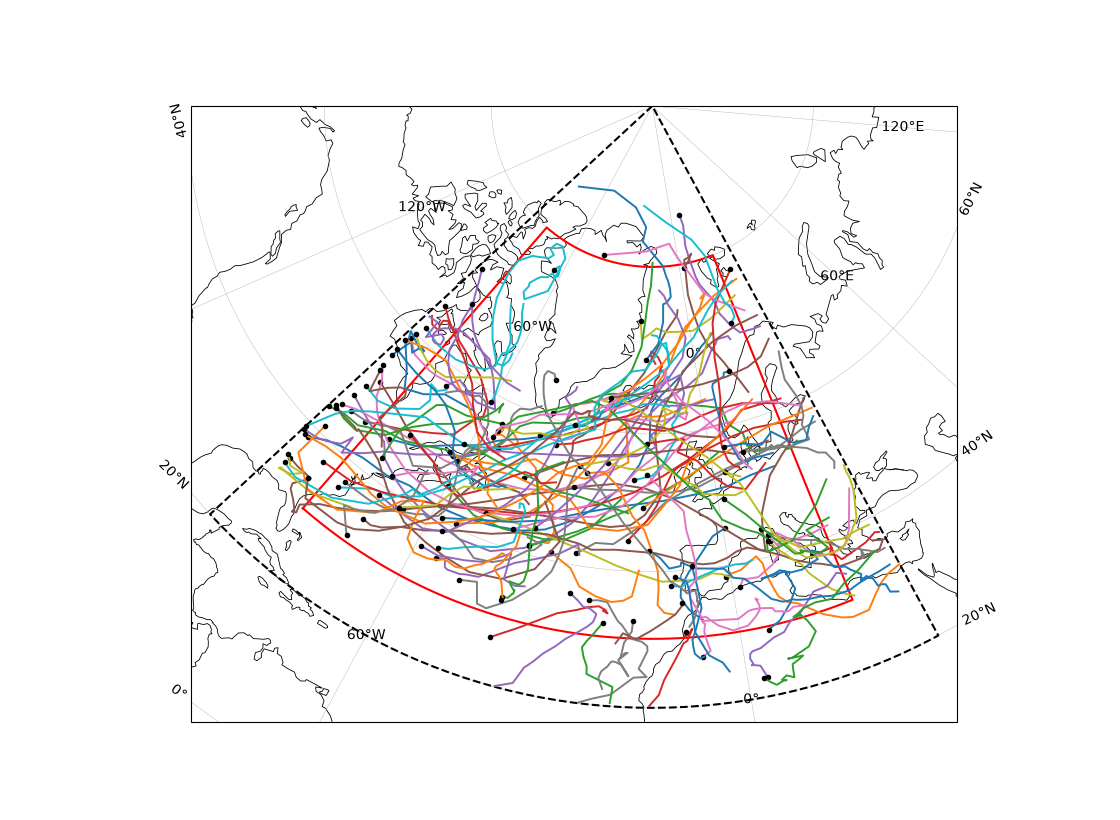

In [11]:
ax = val.plot_regional_tracks(tracks_validation, region=REGION, domain=DOMAIN, summary = summary_validation, object=True)

In [12]:
tracks = pst.load_tracks('/Users/asgerthormann/Documents/uni/master/master_code/master_thesis/trackjson/19981999_DJF_vo.trackjson')

In [13]:
tracks, summary, points = pro.postprocess_tracks(tracks, region=REGION, domain=DOMAIN, time_range=TIME_RANGE,
                       region_criterion="passes", min_points_in_region=1,
                       rsplice_min_points=8, rsplice_max_points=None,
                       rsplice_distance_degrees=9.0, rsplice_distance_mode="endpoint",
                       rsplice_cadence=np.timedelta64(6, "h"),
                       min_peak=None, max_frac_at_edge=0.5,
                       edge_buffer_deg=2.5, drop_time_truncated=False)

In [14]:
summary['vo_peak']

0       0.000082
1       0.000154
2       0.000065
3       0.000121
4       0.000064
          ...   
2010    0.000054
2011    0.000034
2012    0.000064
2013    0.000038
2014    0.000105
Name: vo_peak, Length: 2015, dtype: float64

In [15]:
comparison, matches_df = compare_to_validation(tracks_validation, tracks, matching="global_assignment",
                                               max_mean_separation_deg=2.0, min_overlap_fraction=0.6,
                                               variable="vo")

In [16]:
matches_df

,reference_id,candidate_id,overlap_fraction,overlap_count,mean_sep_km,max_sep_km,ref_points,cand_points,ref_peak,cand_peak,n_eligible_candidates,intensity_bias,intensity_rmse
0,700,27,0.958333,23,95.734488,263.410358,23,25,0.000116,0.000240,1,0.000063,0.000068
1,5300,504,0.933333,14,191.023895,671.732202,14,16,0.000032,0.000115,1,0.000047,0.000058
2,10400,665,0.684211,13,151.395446,345.975839,17,21,0.000021,0.000051,1,0.000019,0.000020
3,20600,152,0.842105,24,114.732554,421.066579,27,30,0.000100,0.000242,1,0.000058,0.000069
4,23100,384,0.941176,8,198.557344,347.069487,8,9,0.000037,0.000061,1,0.000021,0.000021
5,29100,405,0.964706,41,123.538702,529.752413,42,43,0.000087,0.000185,1,0.000039,0.000048
6,31600,252,0.888889,12,80.412771,183.133589,12,15,0.000051,0.000098,1,0.000035,0.000036
7,37800,425,0.967742,15,137.450006,510.489282,16,15,0.000125,0.000244,1,0.000087,0.000091
8,42000,352,0.842105,8,132.374945,247.851890,9,10,0.000024,0.000053,1,0.000019,0.000020
9,45300,850,0.941176,16,108.839841,260.429220,17,17,0.000050,0.000096,1,0.000024,0.000027


/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)
/Users/asgerthormann/mamba/envs/master_env/lib/python3.12/site-packages/shapely/creation.py:730: RuntimeWarning: invalid value encountered in create_collection
  return lib.create_collection(geometries, np.intc(typ), out=out, **kwargs)


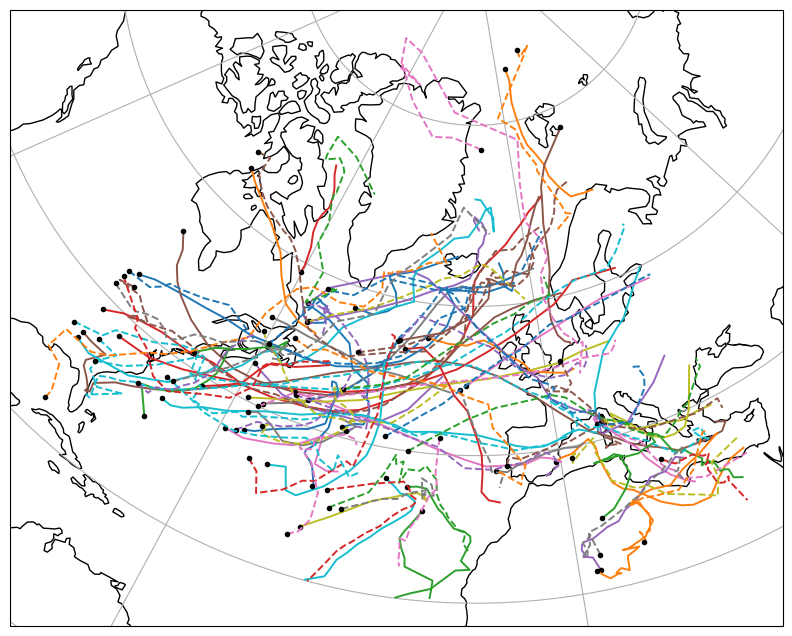

In [39]:
pc= ccrs.PlateCarree()
fig, ax = plt.subplots(figsize=(12, 8), subplot_kw={"projection": ccrs.LambertConformal(central_longitude=-15, central_latitude=55)})
keep = None if summary_validation is None else dict(zip(summary["track_id"], summary["keep"]))
ax.coastlines()
ax.gridlines()
for tr in tracks_validation:
    kept = True if keep is None else keep.get(tr.track_id, True)
    matched = True if tr.track_id in matches_df["reference_id"].values else False
    if kept and matched:
        ax.plot(tr.lons, tr.lats, "-", lw=1.4, transform=pc)
        ax.plot(tr.lons[0], tr.lats[0], "k.", ms=6, transform=pc)
    #else:
        #ax.plot(tr.lons, tr.lats, "-", color="0.75", lw=0.8, transform=pc, zorder=0)
for tr in tracks:
    matched = True if tr.track_id in matches_df["candidate_id"].values else False
    if matched:
        ax.plot(tr.lons, tr.lats, "--" , lw=1.4, transform=pc)
        ax.plot(tr.lons[0], tr.lats[0], "k.", ms=6, transform=pc)
    #else:
        #ax.plot(tr.lons, tr.lats, "-", color="orange", alpha=0.5, lw=0.8, transform=pc, zorder=0)

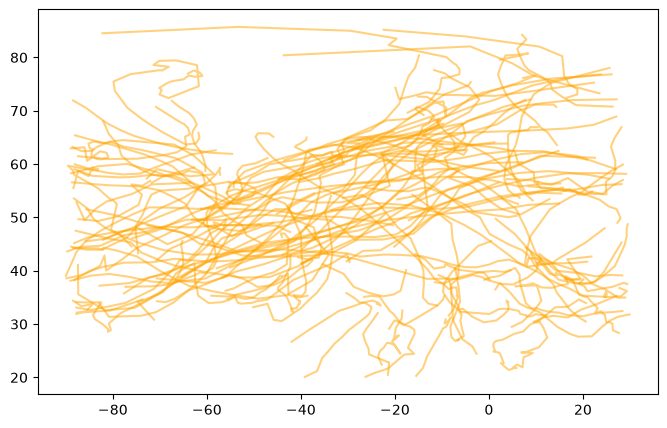

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
for tr in tracks_validation:
    if tr['track_id']
    ax.plot(tr.lons, tr.lats, color='orange', alpha=0.5)

    